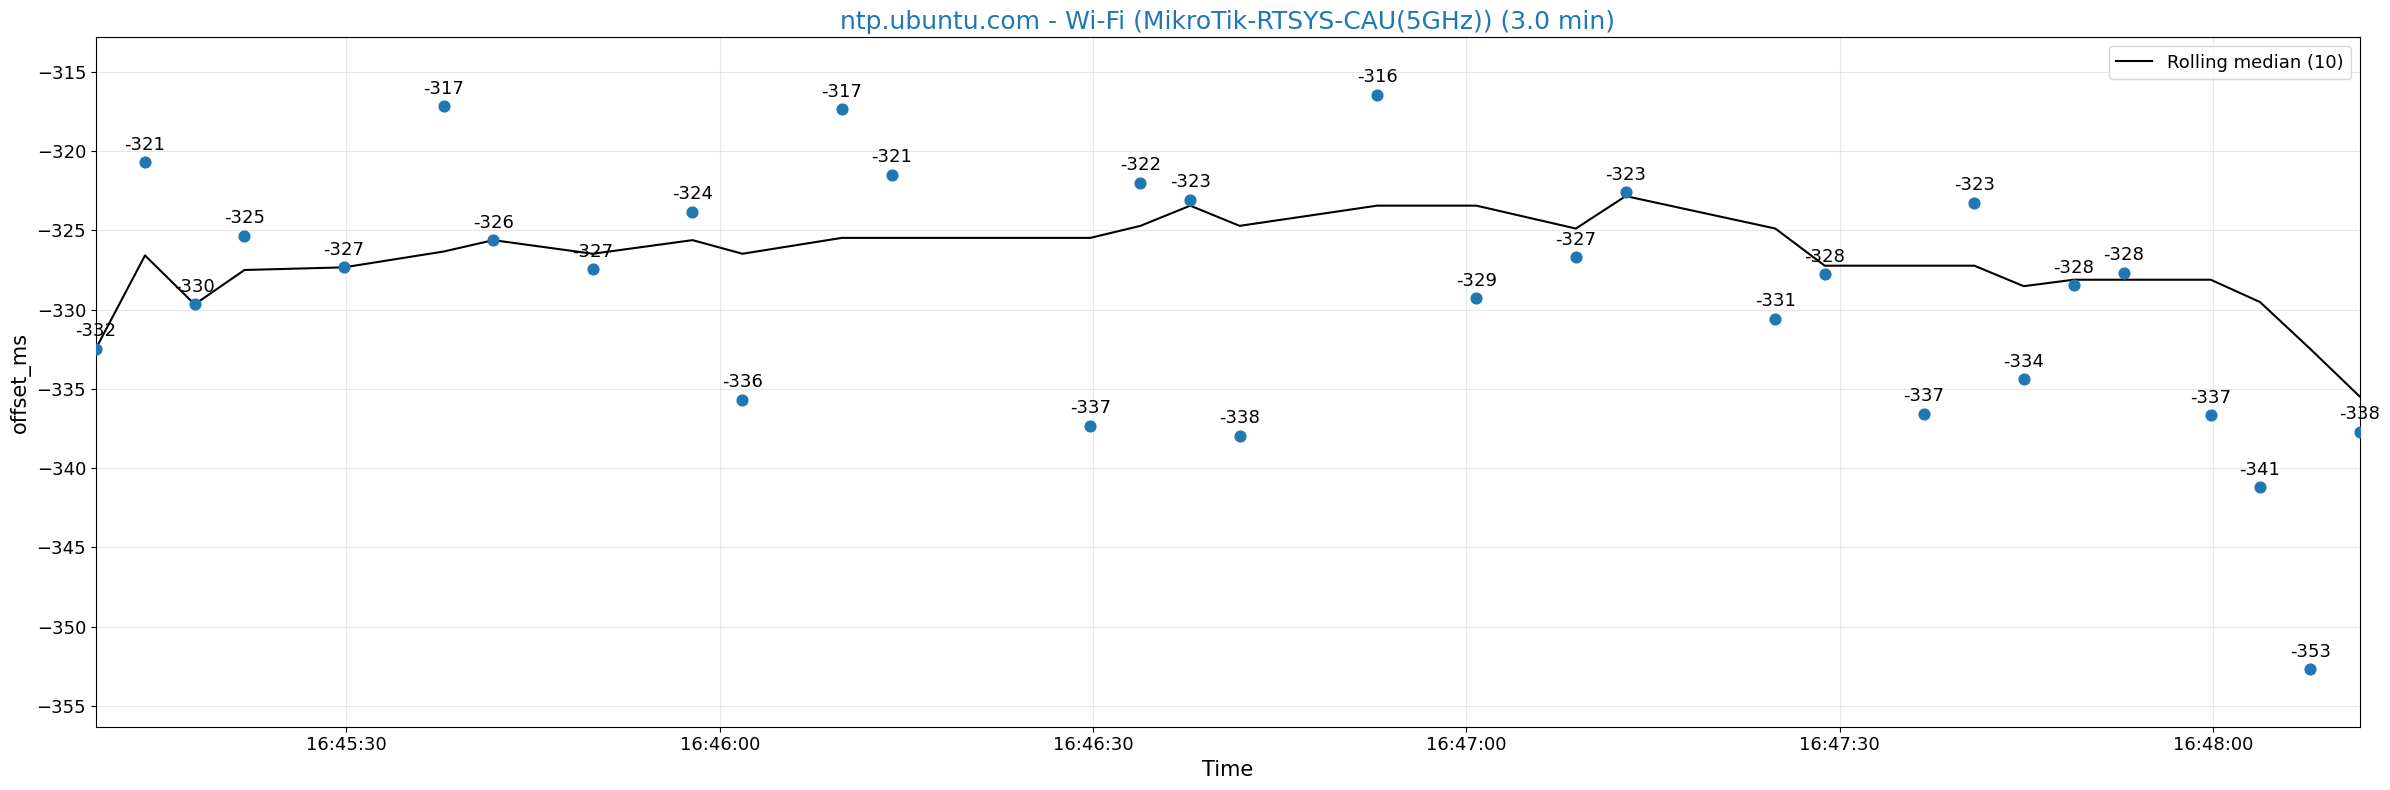

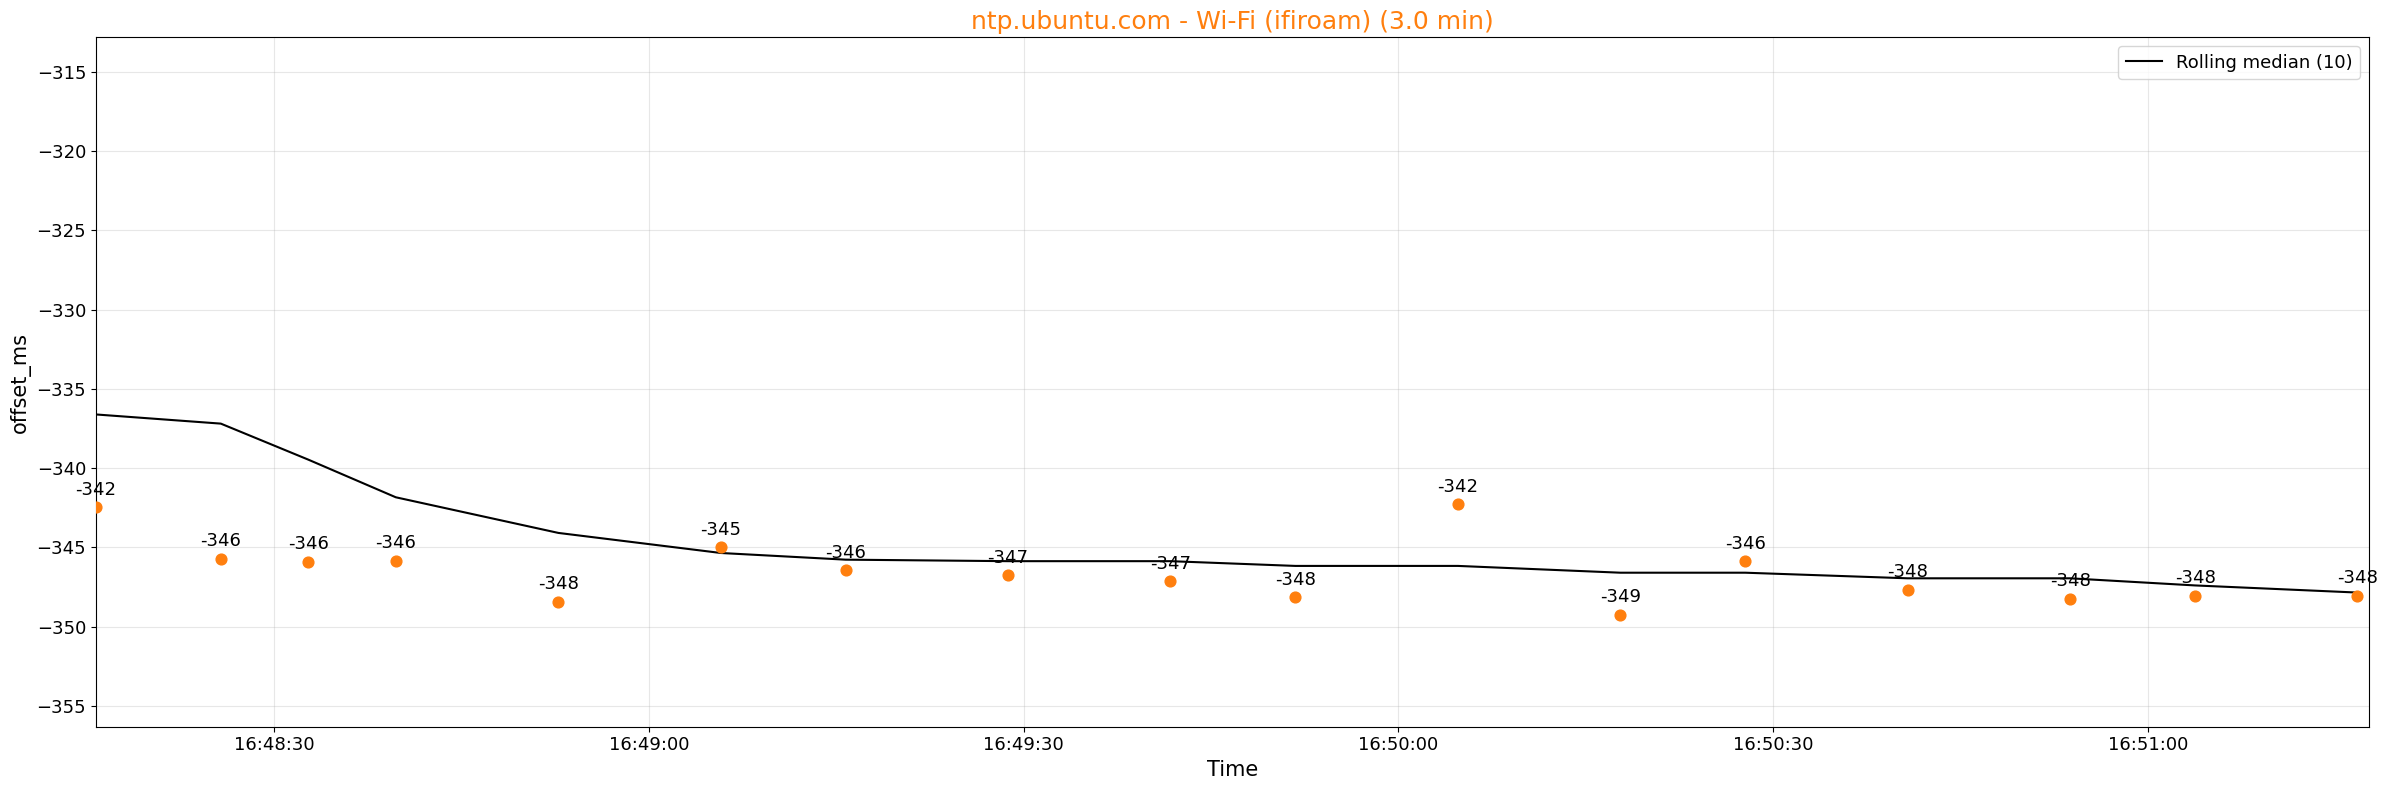

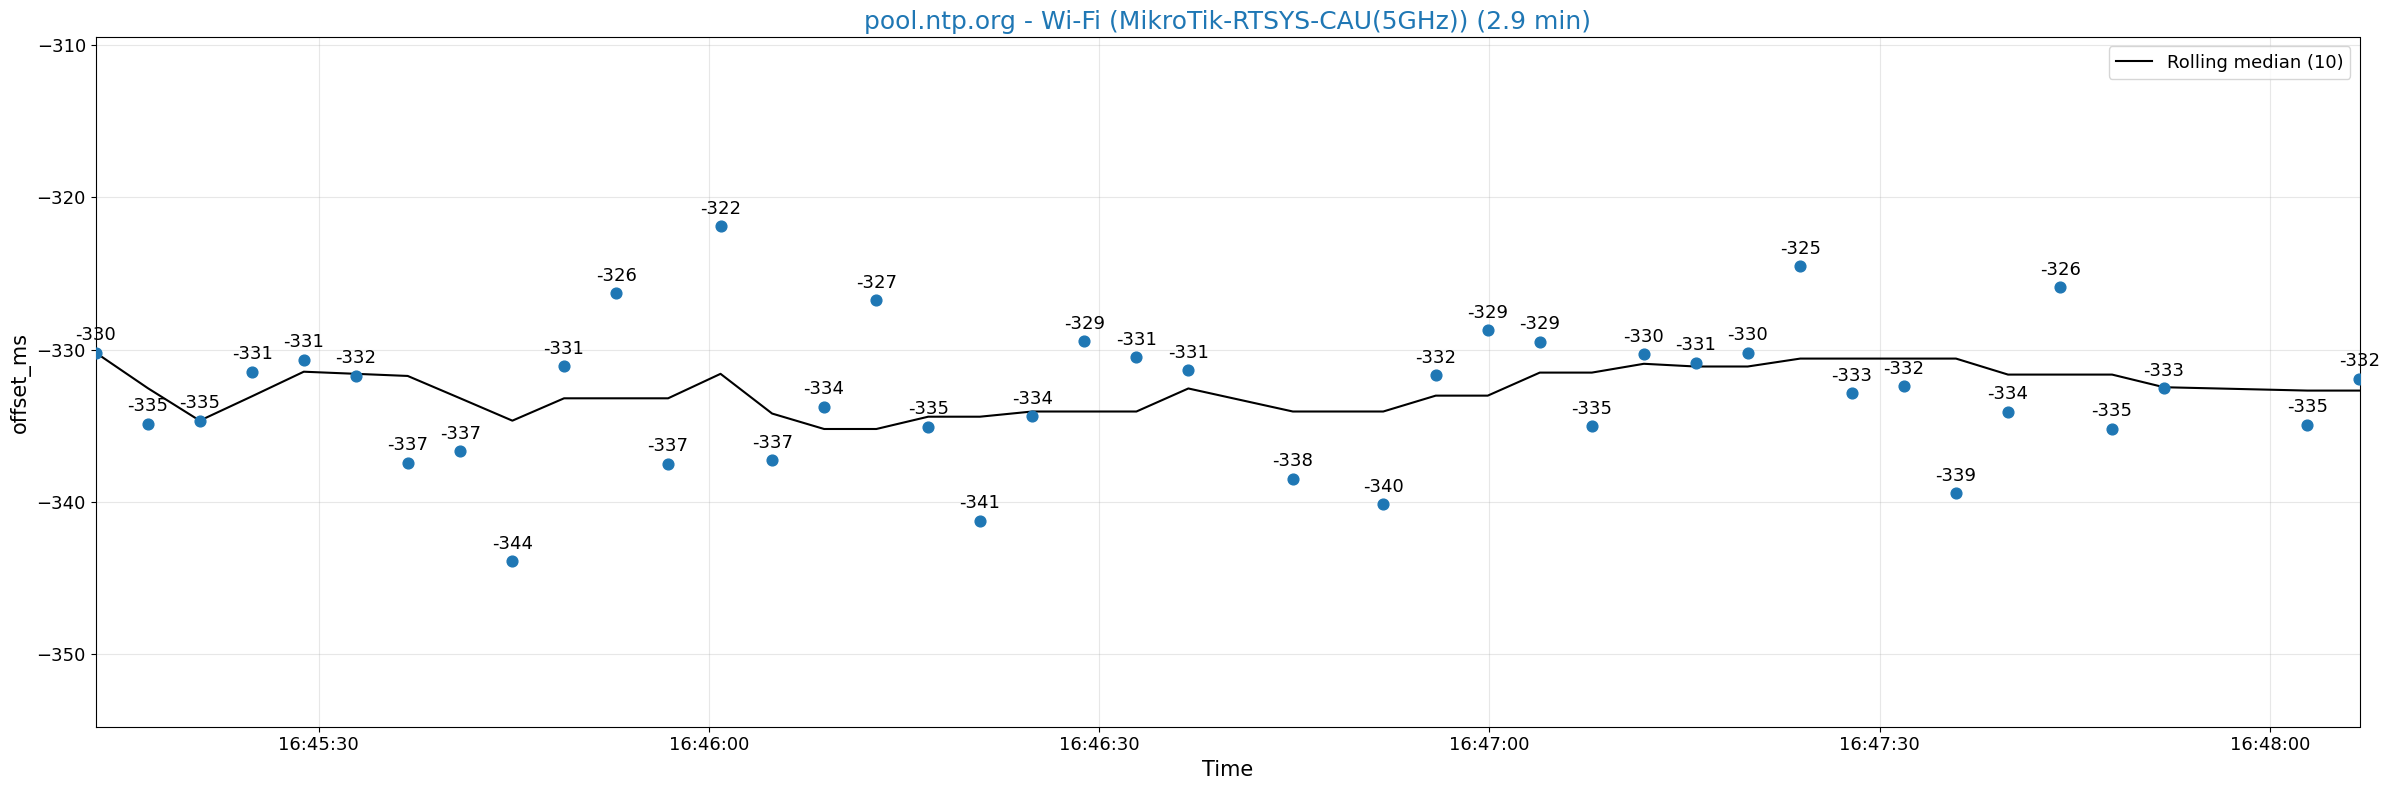

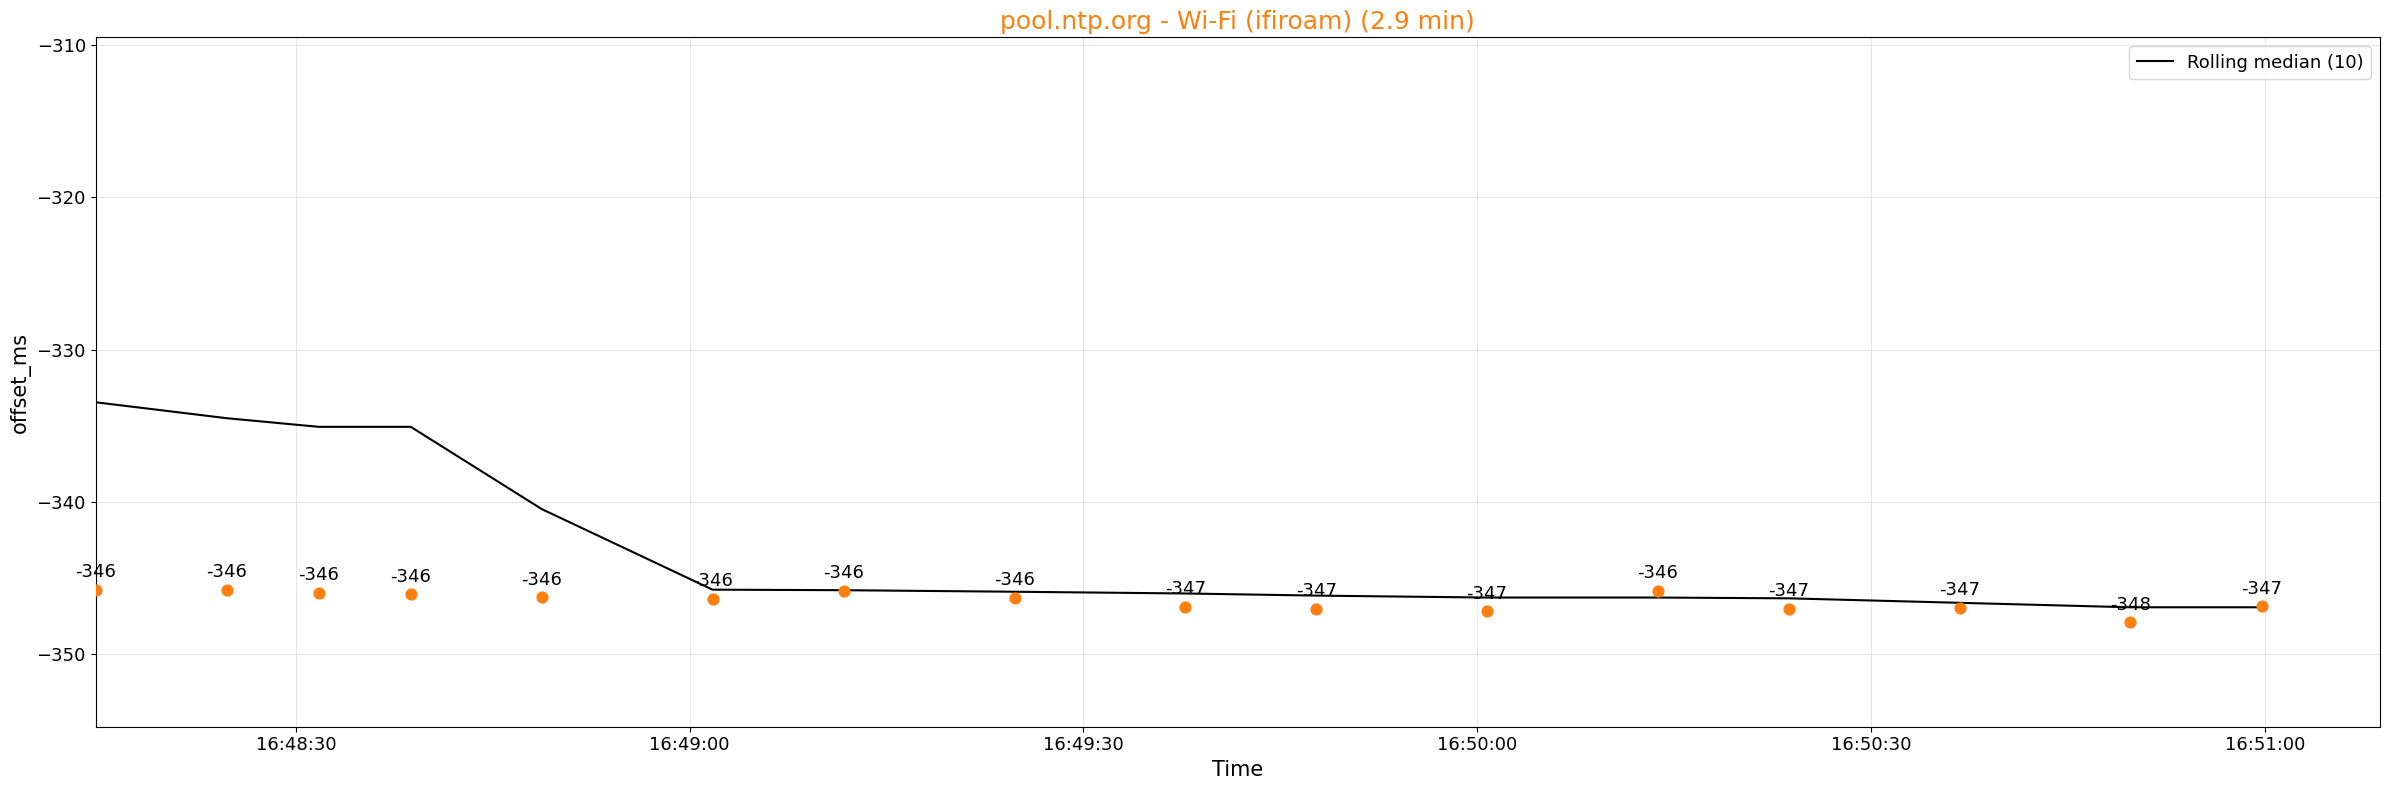

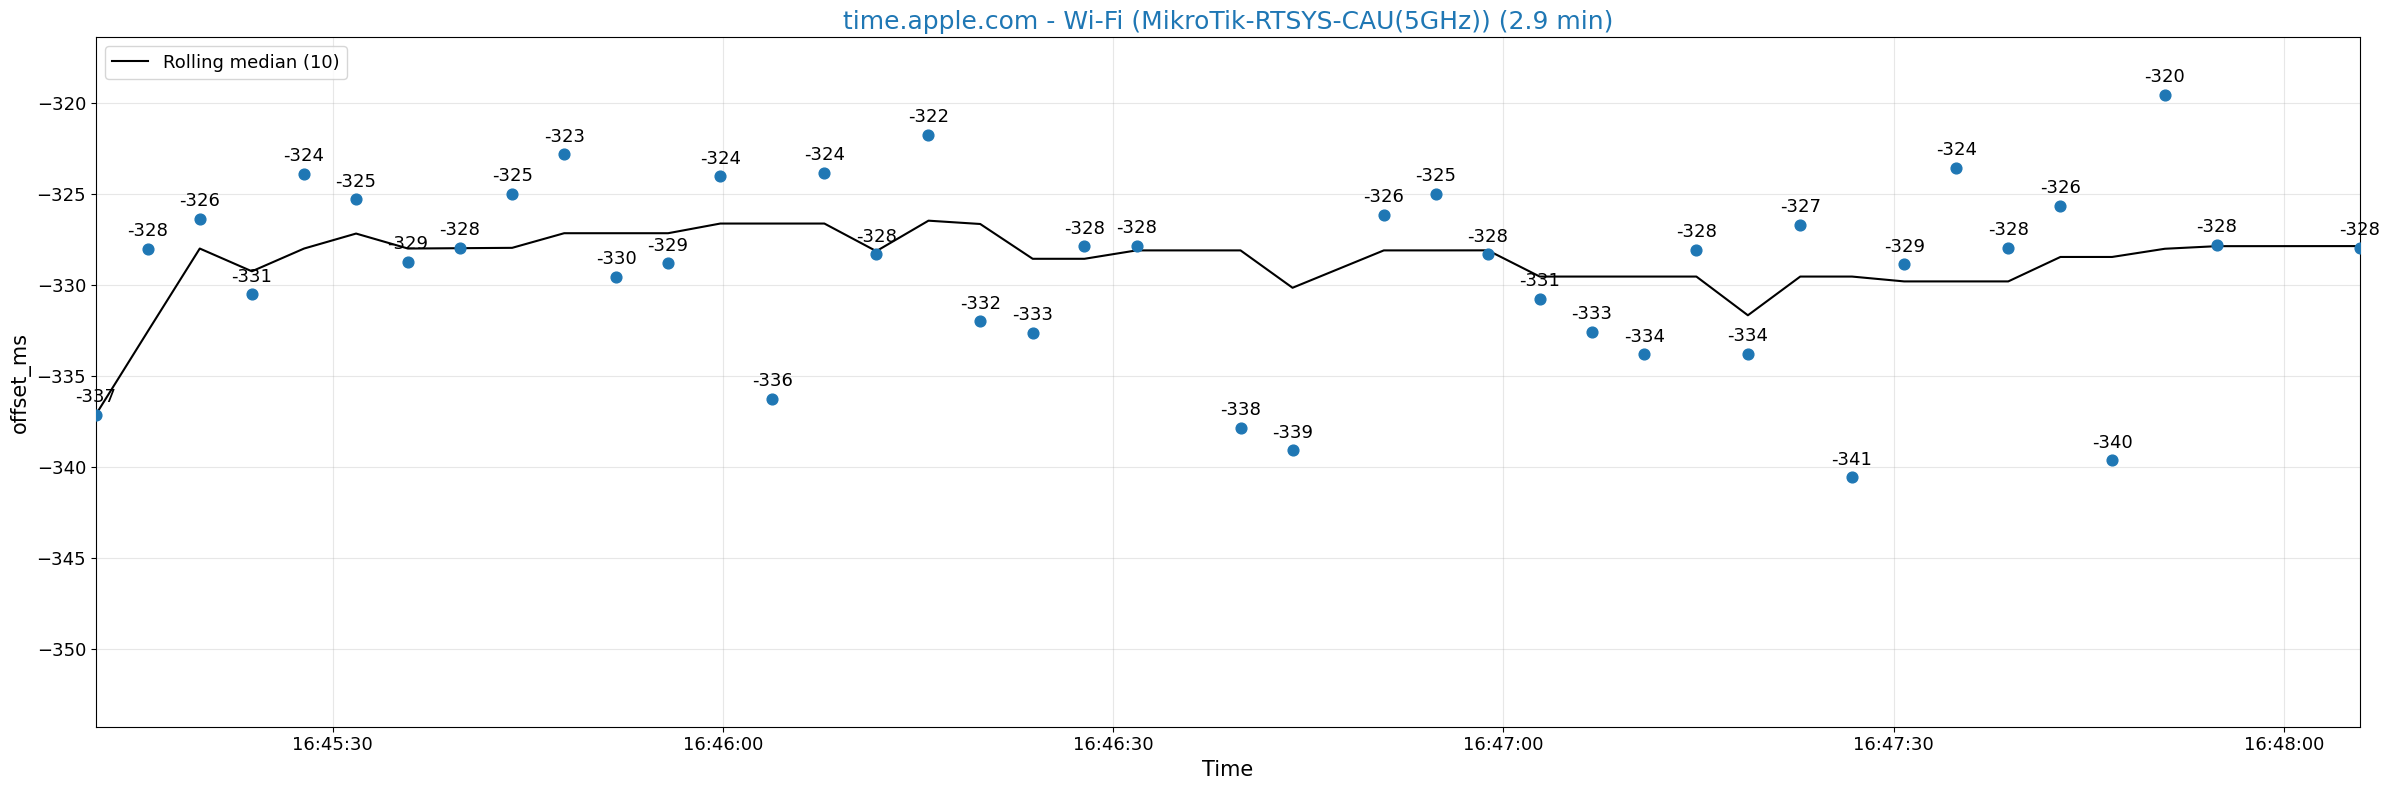

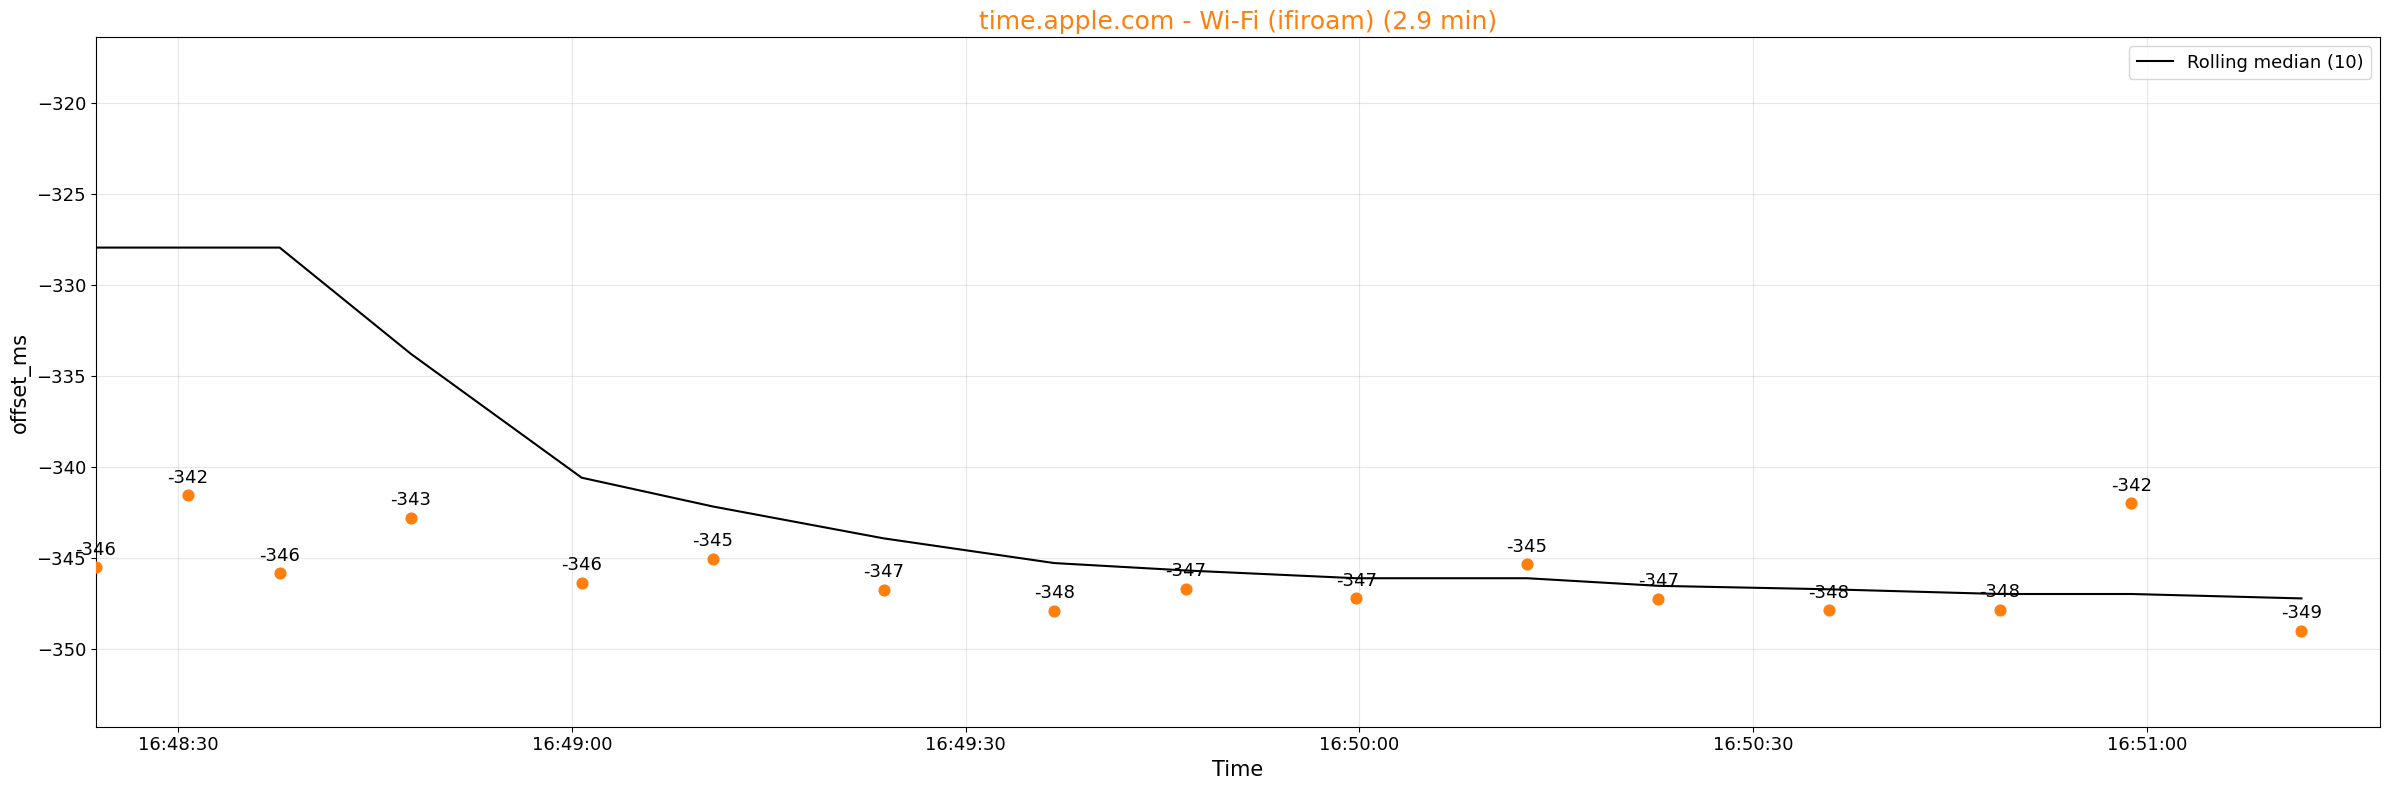

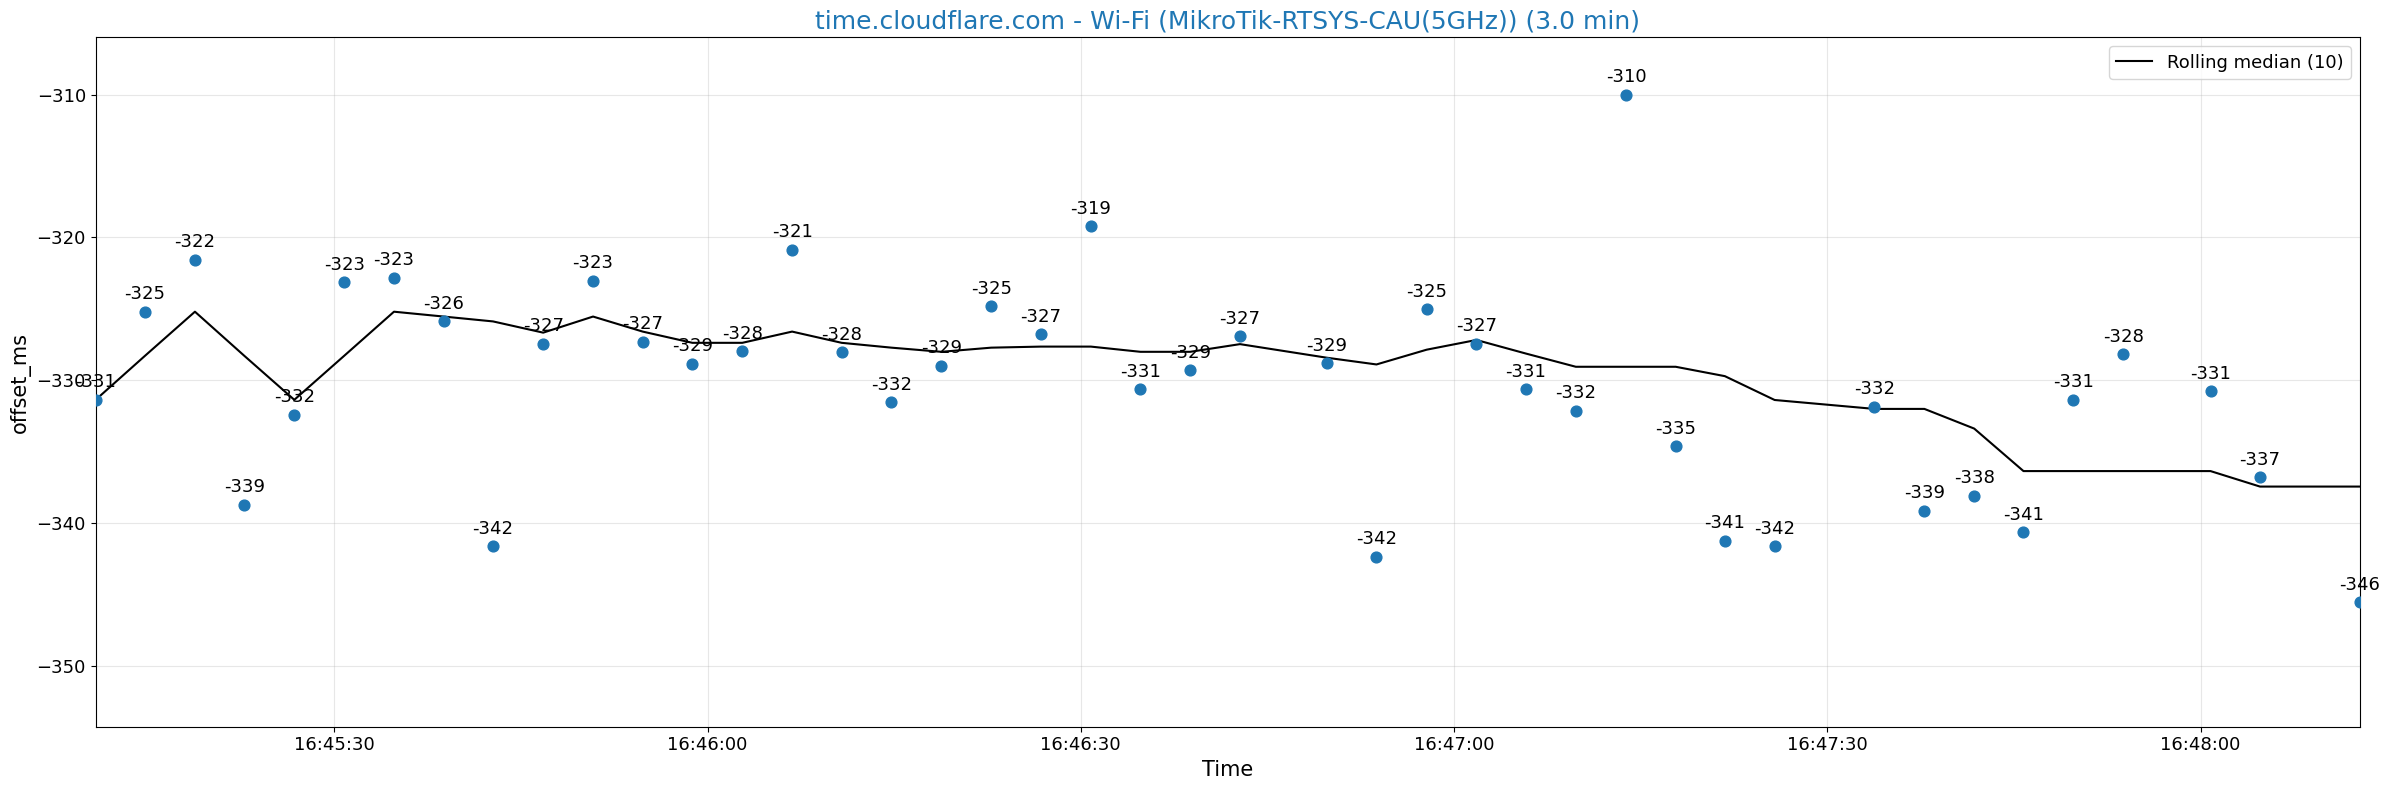

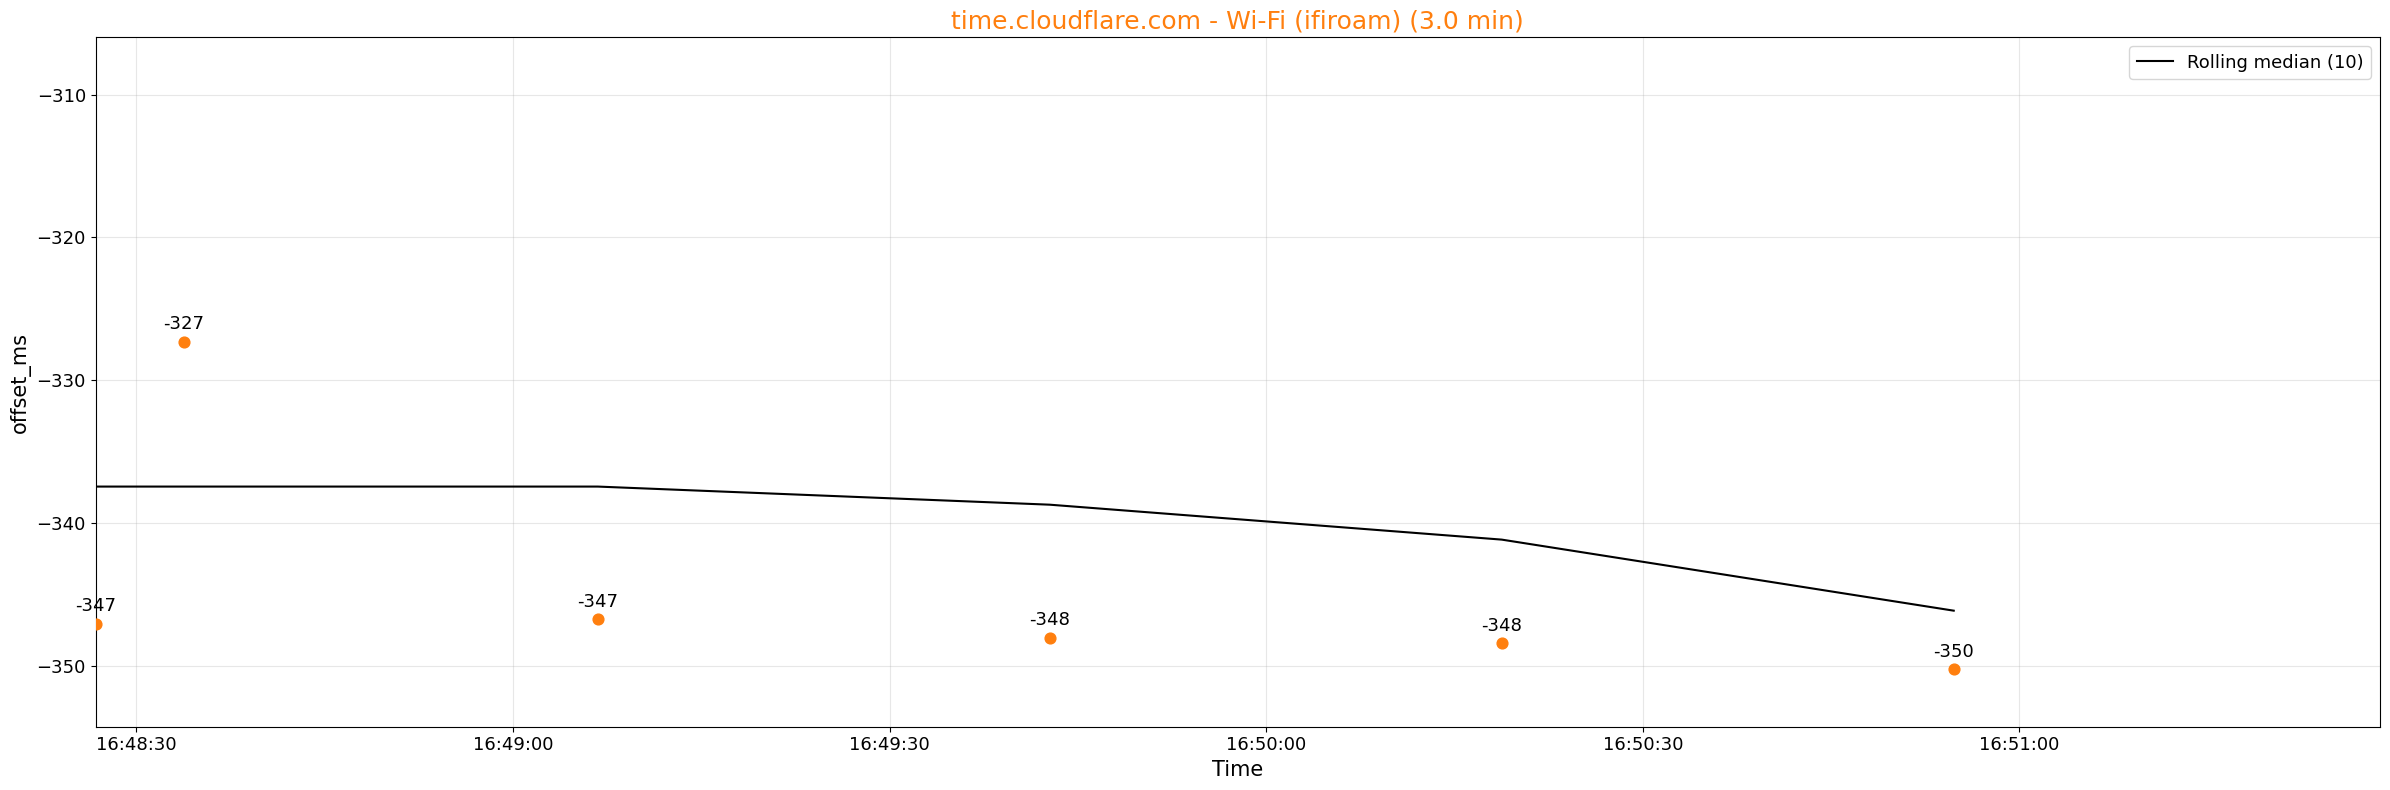

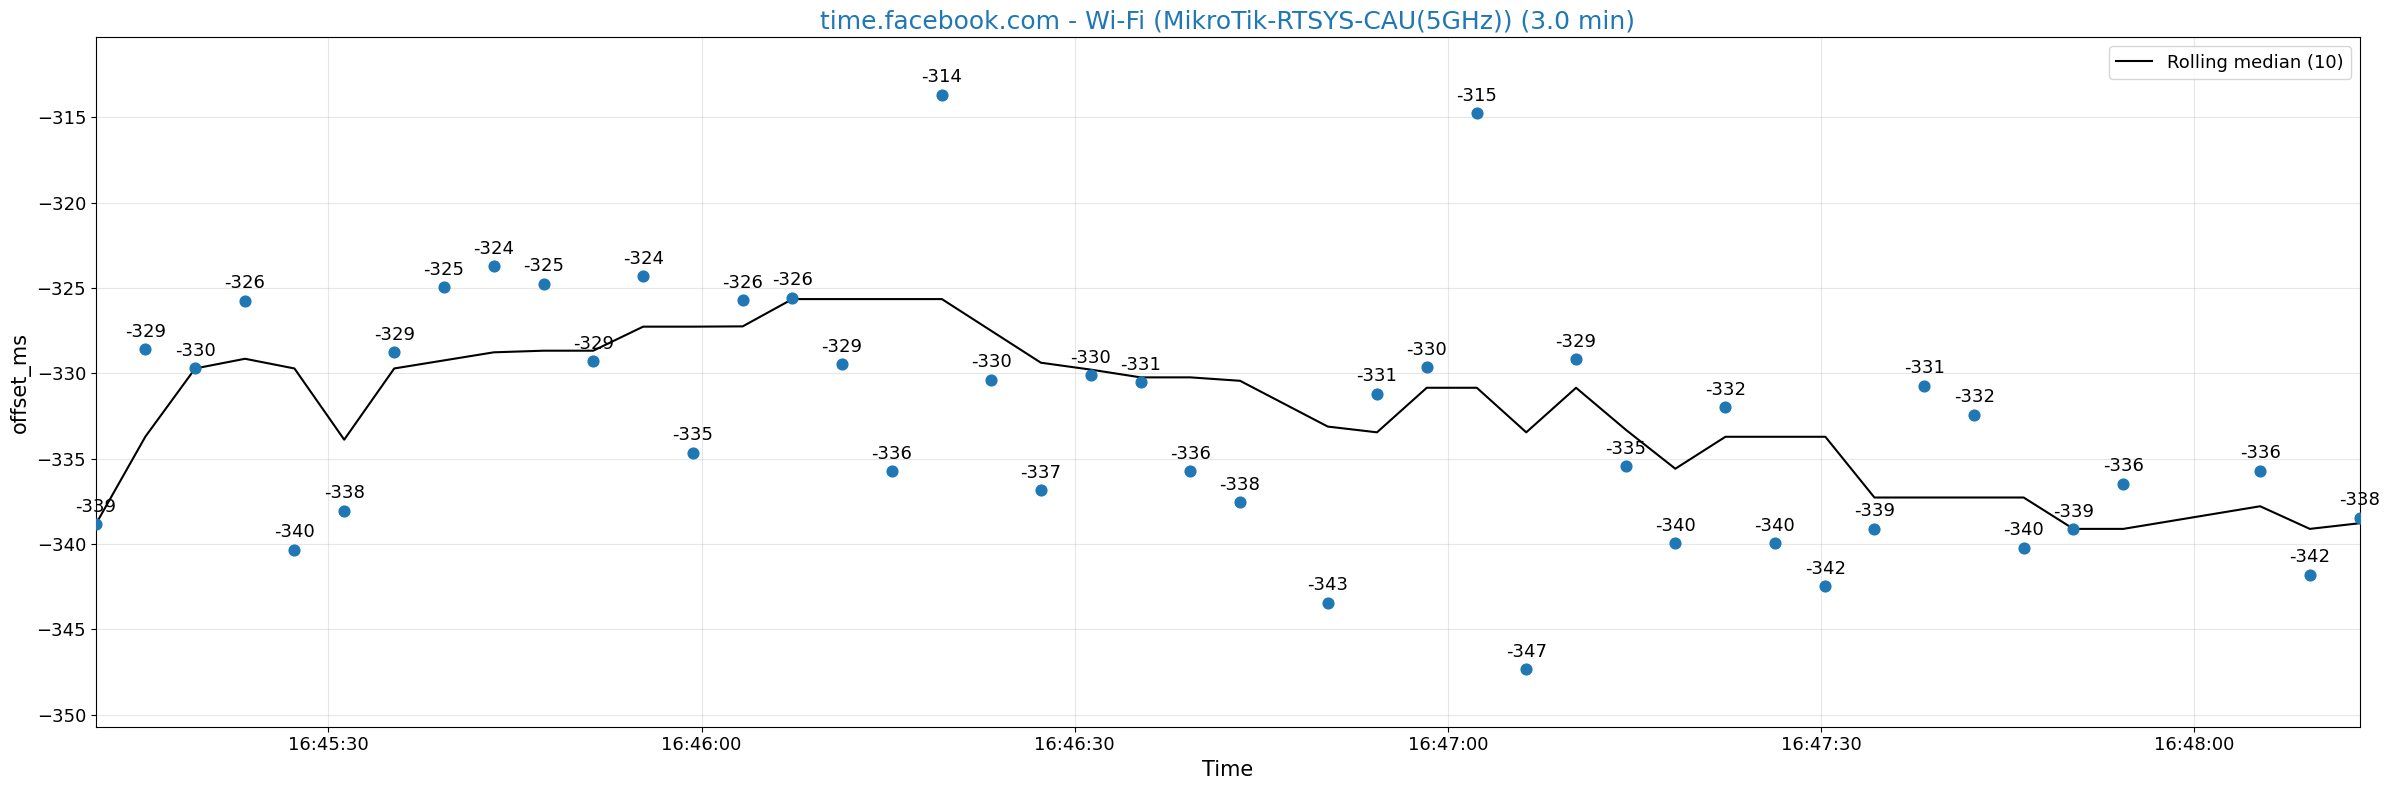

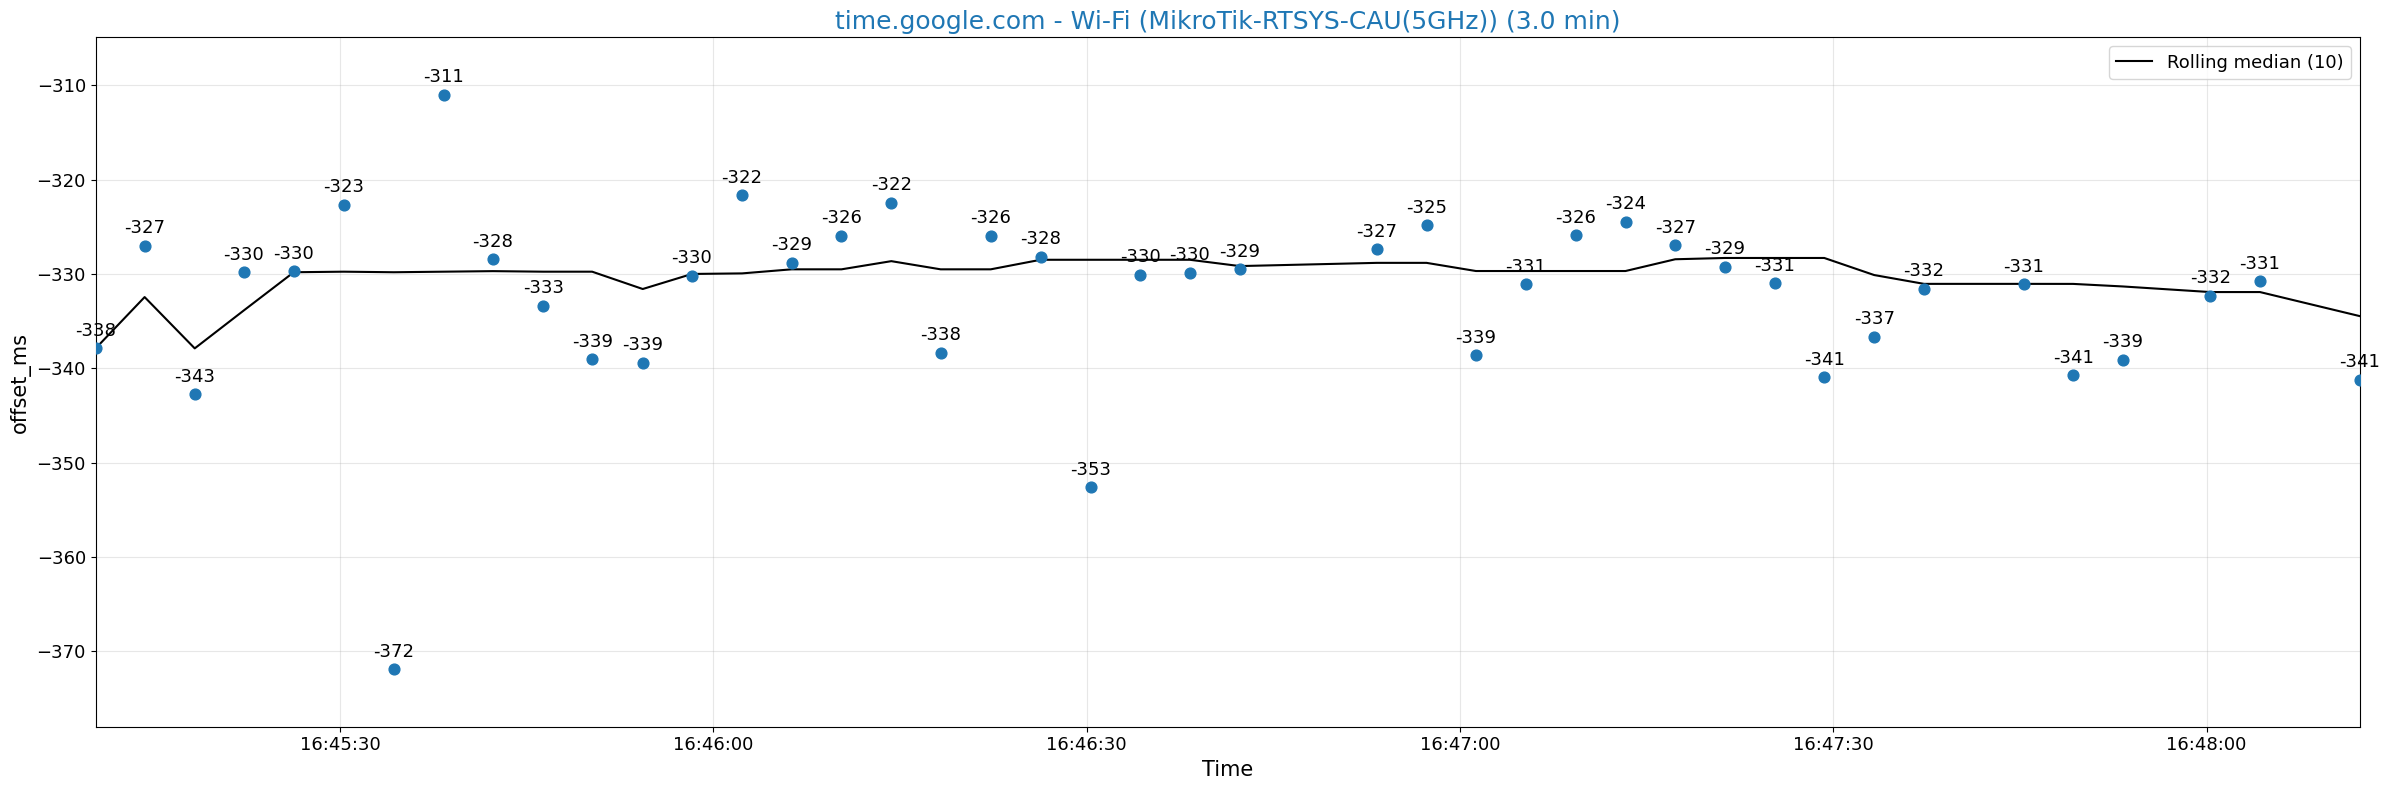

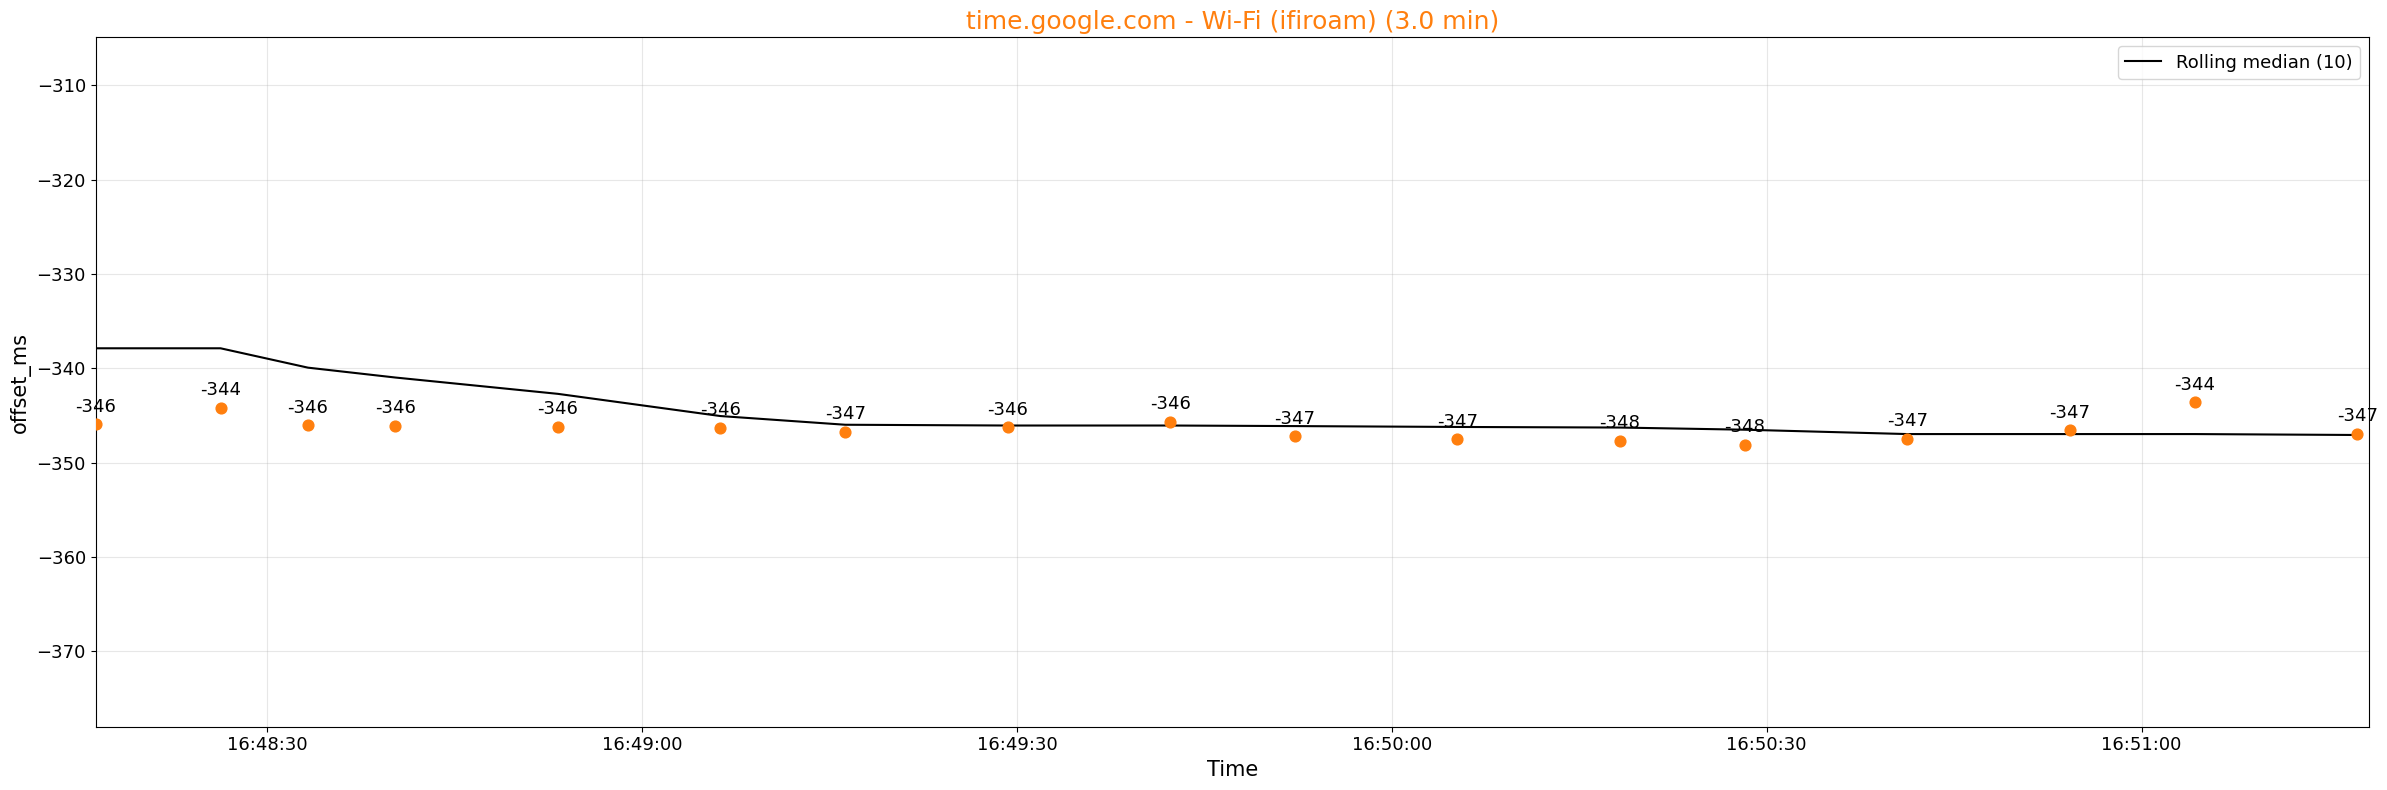

ValueError: min() iterable argument is empty

In [5]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# Folder containing one .jsonl file per NTP server
DATA_DIR = Path('../Desktop/20261102_164509_small')
WINDOW = 10  # rolling median window (samples)
TZ = 'Europe/Berlin'


def load(path):
    df = pd.read_json(path, lines=True)
    df['time'] = pd.to_datetime(df['timestamp_ms'], unit='ms', utc=True).dt.tz_convert(TZ)
    return df.sort_values('time').reset_index(drop=True)


def plot_server(df, name):
    ok = df[df['is_success'] & df['offset_ms'].notna()].copy()
    ok['median'] = ok['offset_ms'].rolling(WINDOW, min_periods=1).median()

    names = list(ok['network_connection'].unique())
    cmap = plt.get_cmap('tab10')
    col = lambda n: cmap(names.index(n) % 10)

    # one separate figure per consecutive network segment, all showing the same time span
    ok['segment'] = ok['network_connection'].ne(ok['network_connection'].shift()).cumsum()
    segs = [g for _, g in ok.groupby('segment')]
    span = min(g['time'].iloc[-1] - g['time'].iloc[0] for g in segs)

    lo, hi = ok['offset_ms'].min(), ok['offset_ms'].max()
    pad = max((hi - lo) * 0.1, 1)

    for seg in segs:
        fig, ax = plt.subplots(figsize=(24, 8))
        start = seg['time'].iloc[0]
        seg = seg[seg['time'] <= start + span]
        n = seg['network_connection'].iloc[0]
        ax.scatter(seg['time'], seg['offset_ms'], s=60, color=col(n), zorder=3)
        ax.plot(seg['time'], seg['median'], color='black', lw=1.5, label=f'Rolling median ({WINDOW})', zorder=2)
        for _, r in seg.iterrows():
            ax.annotate(f"{r['offset_ms']:.0f}", (r['time'], r['offset_ms']), xytext=(0, 9),
                        textcoords='offset points', ha='center', fontsize=13)
        ax.set_xlim(start, start + span)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_title(f'{name} - {n} ({span.total_seconds() / 60:.1f} min)', fontsize=18, color=col(n))
        ax.set_xlabel('Time', fontsize=15)
        ax.set_ylabel('offset_ms', fontsize=15)
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=13)
        ax.tick_params(labelsize=13)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S', tz=TZ))
        fig.tight_layout()
        plt.show()


for f in sorted(DATA_DIR.glob('*.jsonl')):
    plot_server(load(f), f.stem)